In [8]:
import pandas as pd
import numpy as np
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('Datasets/adult/adult.csv')
df.head()

,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,?,103497,Some-college,10,Never-married,?,Own-child,White,Female,0,0,30,United-States,<=50K


In [3]:
# Drop rows with missing values
df.replace("?", np.nan, inplace=True)
df.dropna(inplace=True)
df.head()

,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
5,34,Private,198693,10th,6,Never-married,Other-service,Not-in-family,White,Male,0,0,30,United-States,<=50K


In [4]:
label_encoders = {}
for column in df.columns:
    if df[column].dtype == 'object':
        le = LabelEncoder()
        df[column] = le.fit_transform(df[column])
        label_encoders[column] = le

ID3 Accuracy: 0.8432283029297954
ID3 Decision Tree Evaluation
Accuracy: 0.8432283029297954
              precision    recall  f1-score   support

           0       0.86      0.95      0.90      6842
           1       0.77      0.51      0.61      2203

    accuracy                           0.84      9045
   macro avg       0.81      0.73      0.76      9045
weighted avg       0.84      0.84      0.83      9045



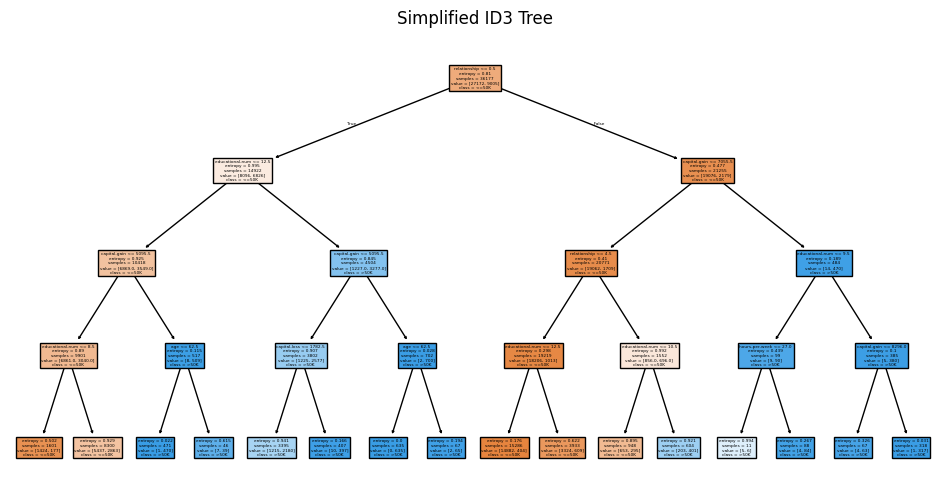

In [16]:
X = df.drop("income", axis=1)
y = df["income"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# ID3 model
id3_model = DecisionTreeClassifier(
    criterion='entropy',    # or 'gini'
    max_depth=4,            # limit depth
    min_samples_split=2,   # don’t split unless node has 20+ samples
    min_samples_leaf=10     # leaf must have 10+ samples
)
id3_model.fit(X_train, y_train)

# Accuracy
y_pred = id3_model.predict(X_test)
print("ID3 Accuracy:", accuracy_score(y_test, y_pred))

print("ID3 Decision Tree Evaluation")
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

# Plot the tree
plt.figure(figsize=(12, 6))
plot_tree(id3_model, feature_names=X.columns, class_names=label_encoders["income"].classes_, filled=True)
plt.title("Simplified ID3 Tree")
plt.show()

# 2


Shape after outlier removal: (41395, 15)


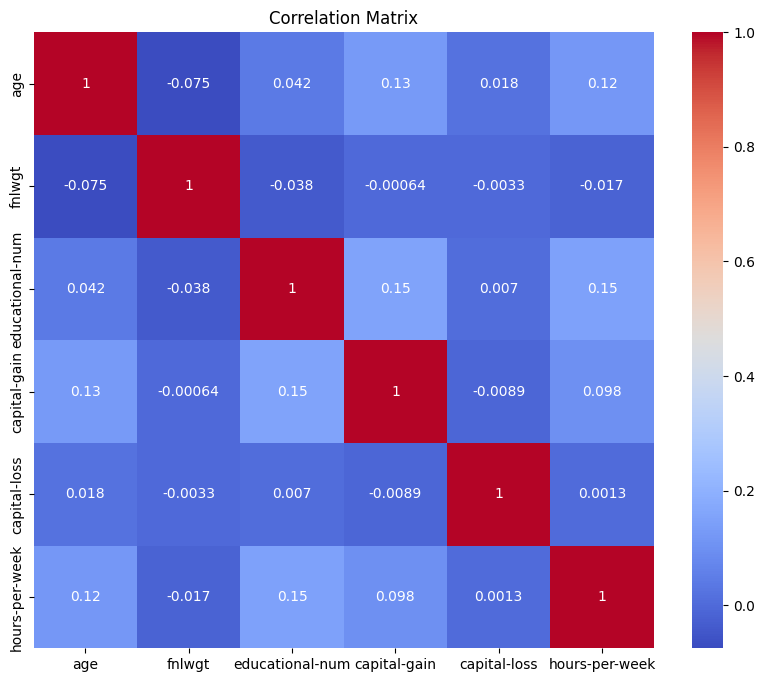

Dropping highly correlated features: []

Final cleaned and normalized dataset shape: (41395, 15)


,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,0.131148,Private,0.432408,11th,0.307692,Never-married,Machine-op-inspct,Own-child,Black,Male,0.00000,0.0,0.492958,United-States,<=50K
1,0.344262,Private,0.154354,HS-grad,0.461538,Married-civ-spouse,Farming-fishing,Husband,White,Male,0.00000,0.0,0.633803,United-States,<=50K
2,0.180328,Local-gov,0.655985,Assoc-acdm,0.692308,Married-civ-spouse,Protective-serv,Husband,White,Male,0.00000,0.0,0.492958,United-States,>50K
3,0.442623,Private,0.297471,Some-college,0.538462,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,0.34882,0.0,0.492958,United-States,>50K
5,0.278689,Private,0.375353,10th,0.230769,Never-married,Other-service,Not-in-family,White,Male,0.00000,0.0,0.352113,United-States,<=50K


In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from scipy import stats
import pandas as pd

df = pd.read_csv('Datasets/adult/adult.csv')
df.head()
 
# Handling Missing Values
# Drop rows with missing values
df.replace("?", np.nan, inplace=True)
df.dropna(inplace=True)
df.head()
 
# Outlier Detection and Removal using Z-score
z_scores = np.abs(stats.zscore(df.select_dtypes(include=np.number)))
df_no_outliers = df[(z_scores < 3).all(axis=1)]
print("\nShape after outlier removal:", df_no_outliers.shape)
df_no_outliers.head()
 
# Redundancy Detection using Correlation Matrix
plt.figure(figsize=(10, 8))
correlation_matrix = df_no_outliers.corr(numeric_only=True)
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

# Drop highly correlated features (threshold > 0.9)
threshold = 0.9
upper = correlation_matrix.where(np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool))
to_drop = [column for column in upper.columns if any(upper[column].abs() > threshold)]
print("Dropping highly correlated features:", to_drop)
df_reduced = df_no_outliers.drop(columns=to_drop)

# Normalization (Min-Max Scaling)
scaler = MinMaxScaler()
numerical_features = df_reduced.select_dtypes(include=np.number).columns
df_reduced[numerical_features] = scaler.fit_transform(df_reduced[numerical_features])

# Final Result
print("\nFinal cleaned and normalized dataset shape:", df_reduced.shape)
display(df_reduced.head())

# 9

Silhouette Score: 0.288


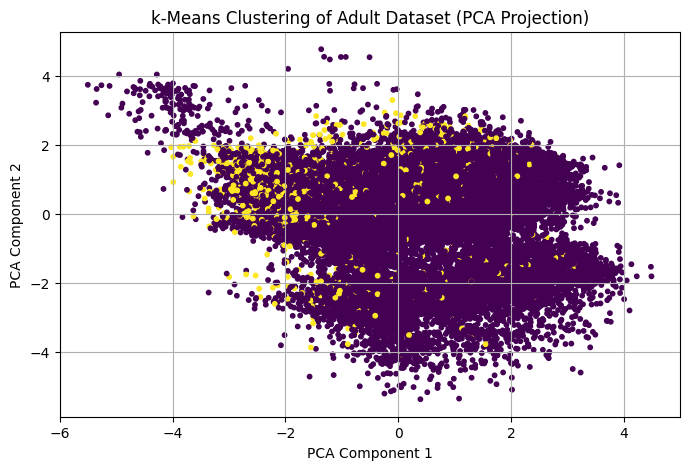

In [22]:
import pandas as pd
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score

df = pd.read_csv('Datasets/adult/adult.csv')
df.head()

# Remove rows with missing values indicated by "?"
df.replace("?", np.nan, inplace=True)
df.dropna(inplace=True)
# Encode categorical features
label_encoders = {}
for column in df.select_dtypes(include='object').columns:
    le = LabelEncoder()
    df[column] = le.fit_transform(df[column])
    label_encoders[column] = le

# Step 3: Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df.drop('income', axis=1))

# Step 4: Apply K-Means clustering
kmeans = KMeans(n_clusters=2, random_state=42)
clusters = kmeans.fit_predict(X_scaled)

# Step 5: Add cluster labels to the original DataFrame
df['cluster'] = clusters

# Step 6: Evaluate clustering quality using silhouette score
sil_score = silhouette_score(X_scaled, clusters)
print(f"Silhouette Score: {sil_score:.3f}")

# Step 7: Visualize using PCA (2D projection)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
plt.figure(figsize=(8, 5))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=clusters, cmap='viridis', s=10)
plt.title('k-Means Clustering of Adult Dataset (PCA Projection)')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.grid(True)
plt.show()

# 7

Accuracy: 0.7903
Classification Report:
               precision    recall  f1-score   support

           0       0.81      0.95      0.87      6842
           1       0.65      0.30      0.41      2203

    accuracy                           0.79      9045
   macro avg       0.73      0.62      0.64      9045
weighted avg       0.77      0.79      0.76      9045



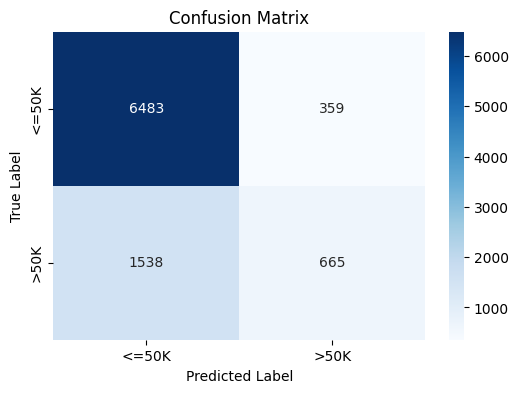

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

df = pd.read_csv('Datasets/adult/adult.csv')
df.head()

# Drop rows with missing values
df.replace("?", np.nan, inplace=True)
df.dropna(inplace=True)
# Encode categorical variables
label_encoders = {}
for col in df.select_dtypes(include=["object"]).columns:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    label_encoders[col] = le  # Save encoders for future use
# Split data
X = df.drop("income", axis=1)
y = df["income"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
# Train Naive Bayes model
model = GaussianNB()
model.fit(X_train, y_train)
# Predictions
y_pred = model.predict(X_test)
# Evaluation
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print("Classification Report:\n", classification_report(y_test, y_pred))
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
# Plot confusion matrix
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["<=50K", ">50K"], yticklabels=["<=50K", ">50K"])
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")

plt.show()


# 8

Model Accuracy: 0.83
              precision    recall  f1-score   support

           0       0.88      0.90      0.89      7479
           1       0.66      0.60      0.63      2290

    accuracy                           0.83      9769
   macro avg       0.77      0.75      0.76      9769
weighted avg       0.83      0.83      0.83      9769



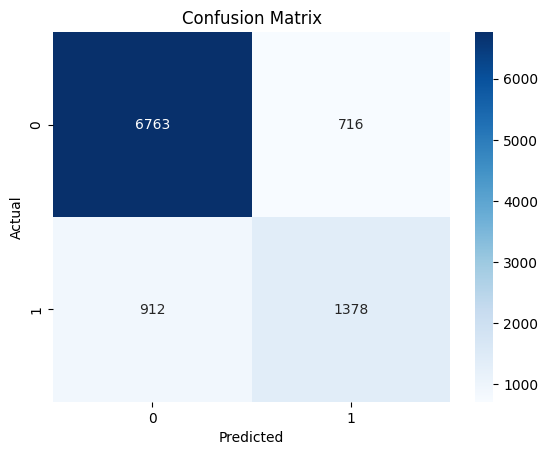

Correct Predictions:
        Actual  Predicted
7762        0          0
23881       0          0
30507       1          1
28911       0          0
43031       0          0

Wrong Predictions:
        Actual  Predicted
19484       0          1
36230       0          1
2372        1          0
29642       0          1
879         1          0


In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

df = pd.read_csv('Datasets/adult/adult.csv')
df.head()

# Preprocessing
df = df.dropna()
label_encoders = {col: LabelEncoder().fit(df[col]) for col in df.select_dtypes(include=['object']).columns}
for col, le in label_encoders.items():
    df[col] = le.transform(df[col])

# Features and target
X = df.drop(columns=["income"])
y = df["income"]

# Train-test split and standardization
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train, X_test = scaler.fit_transform(X_train), scaler.transform(X_test)

# Train KNN model
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
# Predictions and evaluation
y_pred = knn.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy:.2f}")
print(classification_report(y_test, y_pred))

# Confusion matrix
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

# Correct and incorrect predictions
comparison_df = pd.DataFrame({"Actual": y_test, "Predicted": y_pred})
print("Correct Predictions:\n", comparison_df[comparison_df["Actual"] == comparison_df["Predicted"]].head(5))
print("\nWrong Predictions:\n", comparison_df[comparison_df["Actual"] != comparison_df["Predicted"]].head(5))


# 10

In [25]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler, LabelEncoder

df = pd.read_csv('Datasets/adult/adult.csv')
df.head()

# Print column names to verify the dataset structure
print("Column Names in Dataset:", df.columns.tolist())

# Step 2: Data Preprocessing
# Optionally drop redundant columns (e.g., "education.num")
if "education-num" in df.columns:  # Check the exact column name (may be 'education-num' or 'education.num')
    df.drop(["education-num"], axis=1, inplace=True)

# Remove rows with missing values
df.dropna(inplace=True)

# Encode categorical variables using LabelEncoder and store the encoders for later use
label_encoders = {}
for col in df.select_dtypes(include=['object']).columns:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    label_encoders[col] = le  # Store the encoder for potential inverse mapping later

# Define features (X) and target variable (y)
# "income" is the target variable. It is assumed to be encoded as 0 (<=50K) and 1 (>50K).
X = df.drop("income", axis=1)
y = df["income"]

# Scale numeric features using StandardScaler for improved performance
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Step 3: Split the dataset into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# Step 4: Create and train the Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Step 5: Predict on the test set using the trained model
y_pred = model.predict(X_test)

# Evaluate the model's performance using regression metrics
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Mean Squared Error (MSE):", mse)
print("R^2 Score:", r2)

# For classification purposes, threshold the continuous predictions at 0.5
# Values above 0.5 are considered as class 1 (>50K), below or equal to 0.5 as class 0 (<=50K)
y_pred_class = (y_pred > 0.5).astype(int)

# Display the first 10 predictions (true and predicted)
results = pd.DataFrame({
    'True Income': y_test,
    'Predicted (continuous)': y_pred,
    'Predicted Class': y_pred_class
})
print("\nSample Predictions:")
print(results.head(10))

# Decode the numeric predictions back to the original income labels using the stored LabelEncoder
decoded_predictions = label_encoders["income"].inverse_transform(y_pred_class)
decoded_true = label_encoders["income"].inverse_transform(y_test.values)

# Create a DataFrame to compare the true labels, continuous predictions, binary predictions, and decoded labels
results_decoded = pd.DataFrame({
    'True Income': decoded_true,
    'Predicted (continuous)': y_pred,
    'Predicted Binary': y_pred_class,
    'Decoded Prediction': decoded_predictions
})
print("\nSample Results (Decoded):")
print(results_decoded.head(10))


Column Names in Dataset: ['age', 'workclass', 'fnlwgt', 'education', 'educational-num', 'marital-status', 'occupation', 'relationship', 'race', 'gender', 'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income']
Mean Squared Error (MSE): 0.13305238395620564
R^2 Score: 0.25861488207720007

Sample Predictions:
       True Income  Predicted (continuous)  Predicted Class
7762             0                0.192359                0
23881            0                0.125526                0
30507            1                0.522355                1
28911            0                0.230230                0
19484            0                0.235276                0
43031            0               -0.061612                0
28188            0                0.376617                0
12761            1                0.403380                0
40834            0                0.179512                0
27875            0                0.029667                0

Sample Re